# Experiment 16: Comparison of Classification Algorithms
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Compare different types of **classification algorithms** and evaluate their performance.

Algorithms compared: Logistic Regression, K-NN, Naive Bayes, Decision Tree, Random Forest, SVM, Perceptron. The *Breast Cancer Wisconsin* data set is used; metrics are accuracy, precision, recall, F1, ROC-AUC (where available), cross-validation score and training time.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (426, 30) | Test: (143, 30)


In [2]:
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'K-NN (k=5)':          make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    'Naive Bayes':         GaussianNB(),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42),
    'SVM (RBF)':           make_pipeline(StandardScaler(), SVC(random_state=42)),
    'Perceptron':          make_pipeline(StandardScaler(), Perceptron(random_state=42)),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows, preds = [], {}
for name, m in models.items():
    t0 = time.time(); m.fit(X_train, y_train); t = time.time() - t0
    p = m.predict(X_test); preds[name] = p
    if hasattr(m, 'predict_proba'):
        auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    else:
        auc = roc_auc_score(y_test, m.decision_function(X_test))
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, p), 'Precision': precision_score(y_test, p),
                 'Recall': recall_score(y_test, p), 'F1': f1_score(y_test, p), 'ROC-AUC': auc,
                 'CV Acc (mean)': cross_val_score(m, X, y, cv=cv).mean(), 'Train time (s)': t})
results = pd.DataFrame(rows).set_index('Model').round(4).sort_values('Accuracy', ascending=False)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,CV Acc (mean),Train time (s)
Model,,,,,,,
Logistic Regression,0.9860,0.9889,0.9889,0.9889,0.9977,0.9737,0.0047
K-NN (k=5),0.9790,0.9677,1.0000,0.9836,0.9845,0.9631,0.0013
SVM (RBF),0.9790,0.9888,0.9778,0.9832,0.9969,0.9772,0.0039
Perceptron,0.9650,0.9885,0.9556,0.9718,0.9971,0.9508,0.0020
Random Forest,0.9580,0.9565,0.9778,0.9670,0.9949,0.9543,0.2845
Naive Bayes,0.9371,0.9263,0.9778,0.9514,0.9893,0.9385,0.0010
Decision Tree,0.9371,0.9551,0.9444,0.9497,0.9186,0.9280,0.0049


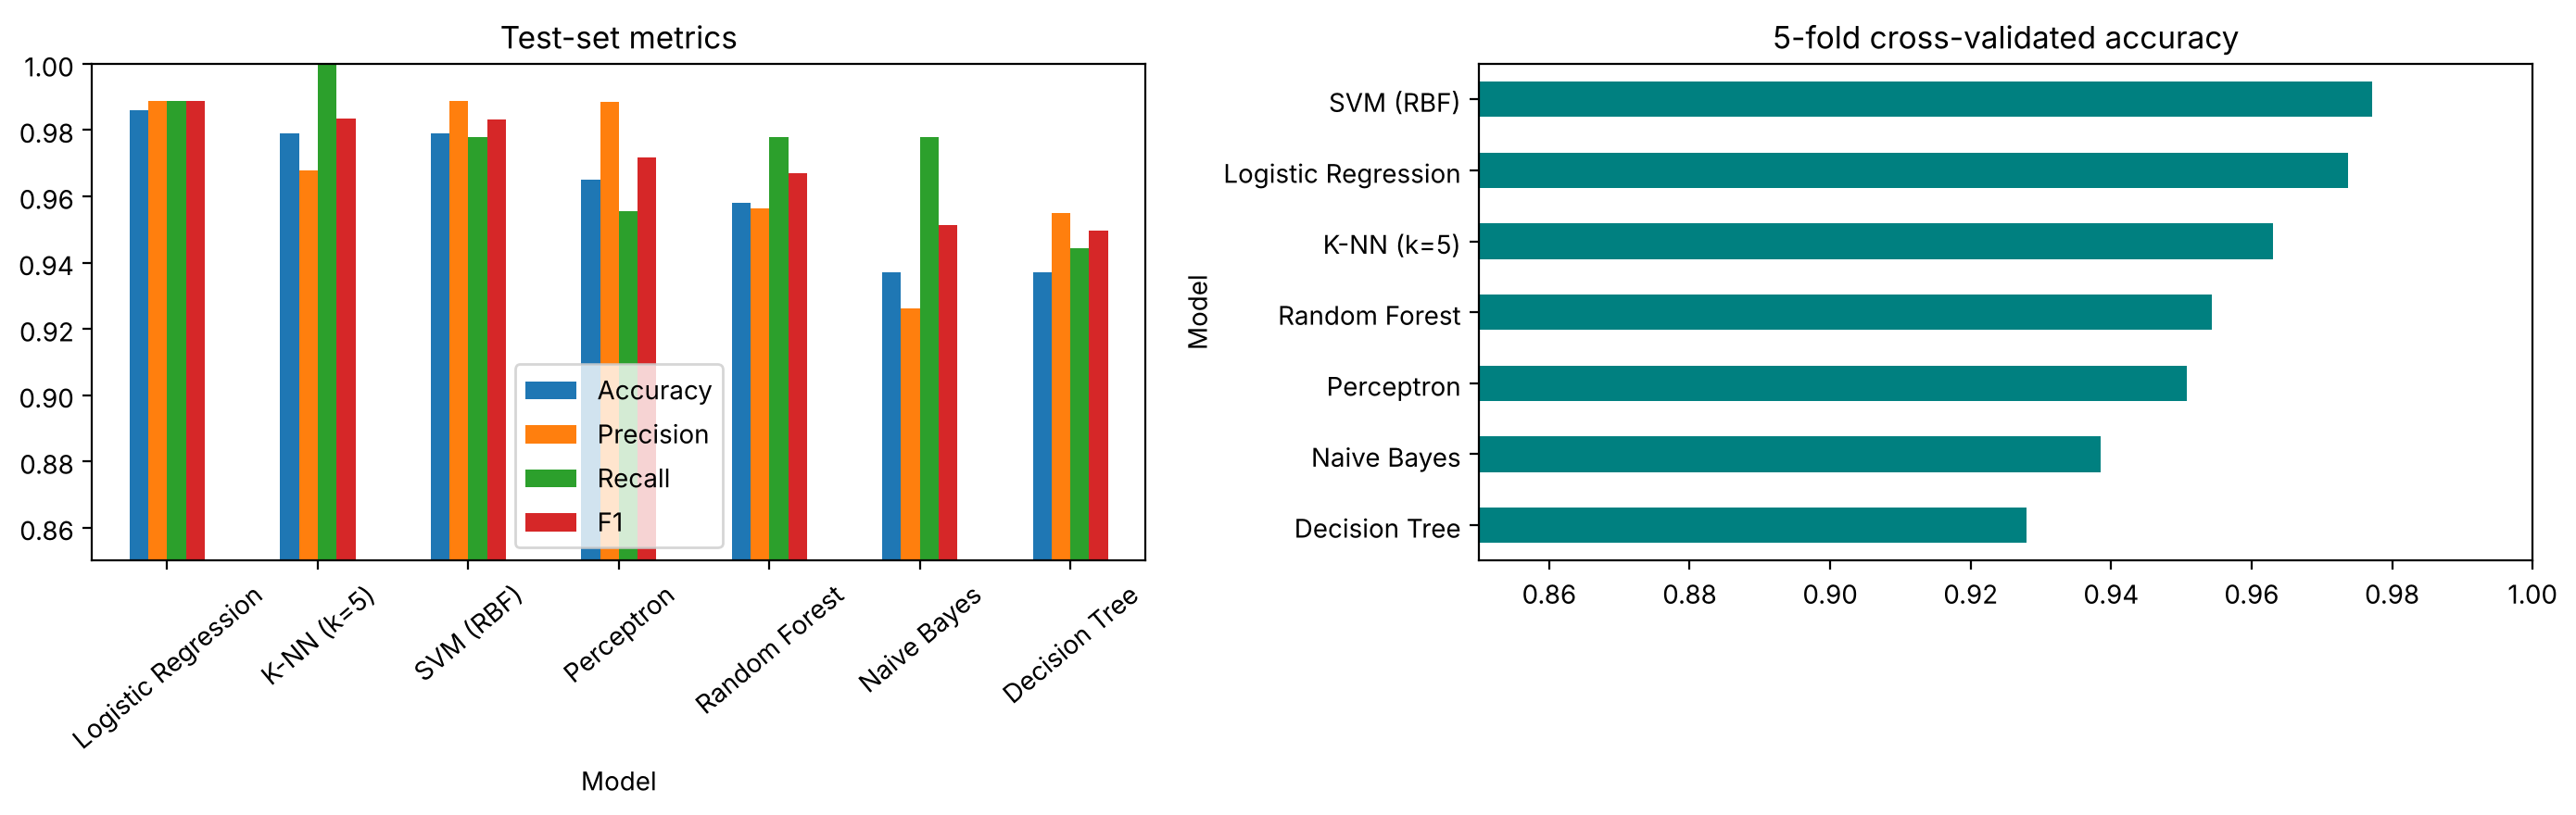

Best model by test accuracy: Logistic Regression


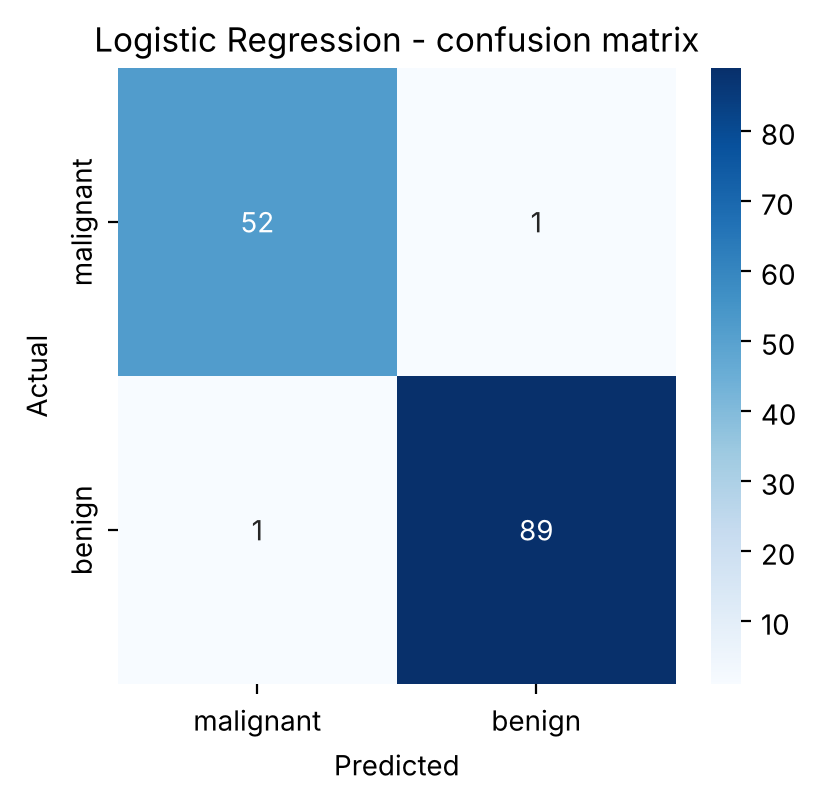

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
results[['Accuracy', 'Precision', 'Recall', 'F1']].plot.bar(ax=ax[0], ylim=(0.85, 1.0))
ax[0].set_title('Test-set metrics'); ax[0].tick_params(axis='x', rotation=40)
results['CV Acc (mean)'].sort_values().plot.barh(ax=ax[1], color='teal', xlim=(0.85, 1.0))
ax[1].set_title('5-fold cross-validated accuracy')
plt.tight_layout(); plt.show()

best = results.index[0]
print('Best model by test accuracy:', best)
plt.figure(figsize=(4.5, 4))
sns.heatmap(confusion_matrix(y_test, preds[best]), annot=True, fmt='d', cmap='Blues',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.title(f'{best} - confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

## Result
All algorithms perform well on this data set (93-99 % test accuracy). Logistic Regression, K-NN and SVM lead, Random Forest and the Perceptron follow, and Naive Bayes and the single Decision Tree are lowest; the table also shows the speed differences (Random Forest is the slowest to train). The best model by test accuracy is Logistic Regression, and cross-validation gives a similar ranking.